<a href="https://colab.research.google.com/github/marrowqq/AIMLDMLLLM/blob/main/LR2_Kashin_AVT_314.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №2
### «Классификация данных. Нейронные сети»

**Дисциплина:** Системы искусственного интеллекта и машинное обучение  
**Выполнил:** Кашин А.В., группа АВТ-314  
**Проверил:** Антонянц Е.Н.  
**Новосибирск, 2026**

В работе решается задача классификации датасета **Iris** пятью классическими методами из Scikit-Learn и строится нейронная сеть на TensorFlow/Keras с мониторингом обучения в TensorBoard.

## 1. Импорт библиотек и настройка воспроизводимости

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score, roc_curve
)
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

%matplotlib inline

## 2. Загрузка и анализ данных (датасет Iris)

Встроенный датасет Фишера: 150 наблюдений, 3 класса (setosa, versicolor, virginica), 4 признака. Датасет сбалансирован, не содержит пропусков и дубликатов.

In [2]:
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
class_names = iris.target_names

df = pd.DataFrame(X, columns=feature_names)
df['class'] = iris.target_names[y]

print('Размер матрицы признаков:', X.shape)
print('Классы:', class_names)
print('Число образцов в классе:')
print(df['class'].value_counts())
print('Пропуски:', df.isna().sum().sum())
print('Дубликаты:', df.duplicated().sum())

Размер матрицы признаков: (150, 4)
Классы: ['setosa' 'versicolor' 'virginica']
Число образцов в классе:
class
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64
Пропуски: 0
Дубликаты: 1


In [3]:
print('Описательная статистика признаков')
df.describe().T.round(2)

Описательная статистика признаков


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.84,0.83,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.06,0.44,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.76,1.77,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.20,0.76,0.1,0.3,1.30,1.8,2.5


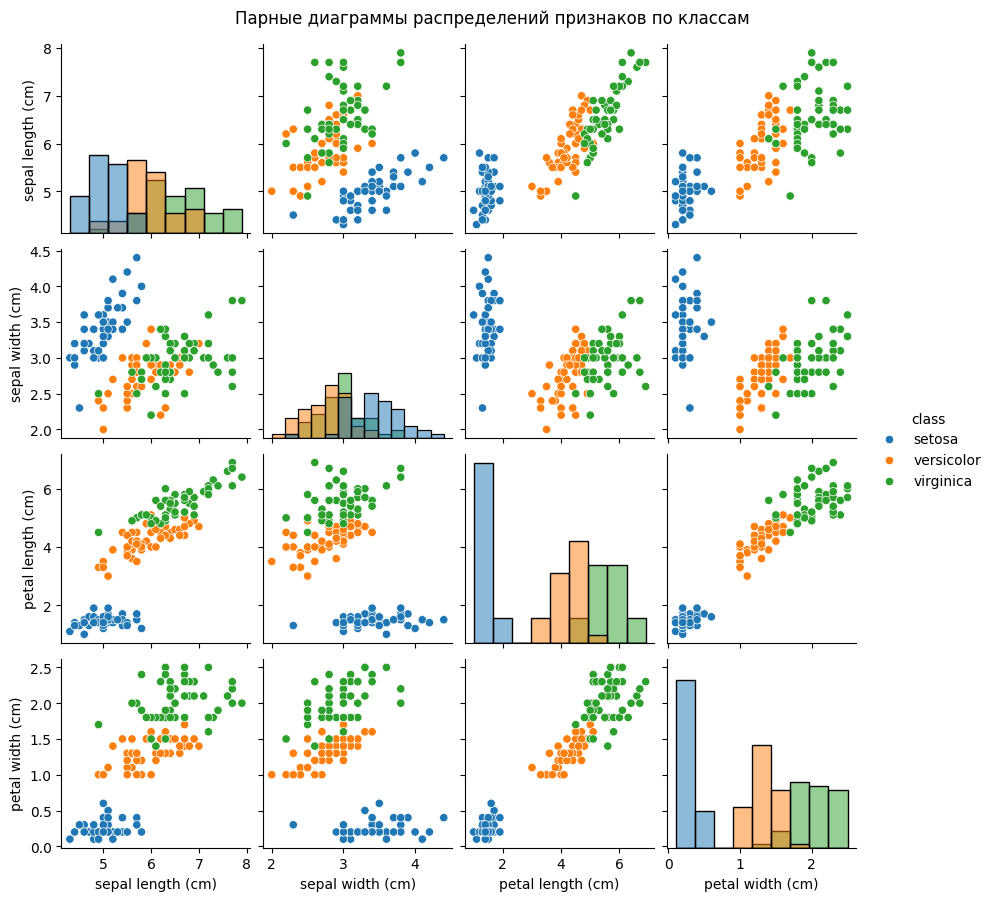

In [4]:
# Рисунок 1 — парные диаграммы распределений признаков по классам
sns.pairplot(df, hue='class', diag_kind='hist', height=2.2)
plt.suptitle('Парные диаграммы распределений признаков по классам', y=1.02)
plt.show()

**Пояснение к рисунку 1.** На парных диаграммах видно, что класс *setosa* (синий) хорошо отделён от двух других уже по длине и ширине лепестка. Классы *versicolor* и *virginica* частично перекрываются по чашелистику, но почти полностью разделяются по признакам лепестка. Поэтому даже простые линейные методы дают высокое качество — классы почти линейно разделимы.


## 3. Разбиение выборки

70% данных — обучение (105 образцов), 30% — тест (45 образцов), `random_state=42`, стратификация для равного распределения классов.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

print(f'Обучающая выборка: {X_train.shape[0]} образцов')
print(f'Тестовая выборка:   {X_test.shape[0]} образцов')
print('Распределение классов в тесте:', np.bincount(y_test))

Обучающая выборка: 105 образцов
Тестовая выборка:   45 образцов
Распределение классов в тесте: [15 15 15]


## 4. Функции оценки и сравнения классификаторов

In [6]:
def evaluate_model(model, X_train_f, y_train_f, X_test_f, y_test_f, name):
    """Обучает модель и возвращает метрики на тестовой выборке."""
    model.fit(X_train_f, y_train_f)
    y_pred = model.predict(X_test_f)
    acc  = accuracy_score(y_test_f, y_pred)
    prec = precision_score(y_test_f, y_pred, average='macro', zero_division=0)
    rec  = recall_score(y_test_f, y_pred, average='macro', zero_division=0)
    f1   = f1_score(y_test_f, y_pred, average='macro', zero_division=0)
    if hasattr(model, 'predict_proba'):
        proba = model.predict_proba(X_test_f)
    else:
        proba = model.decision_function(X_test_f)
    auc = roc_auc_score(y_test_f, proba, multi_class='ovr') if proba.ndim > 1 else np.nan
    return {'model': name, 'accuracy': acc, 'precision': prec,
            'recall': rec, 'f1': f1, 'auc_roc': auc,
            'y_pred': y_pred, 'proba': proba}

## 5. Методы классификации

### 5.1 Наивный байесовский классификатор (GaussianNB)

Основан на теореме Байеса с допущением о независимости признаков при заданном классе.

In [7]:
nb = GaussianNB()
r_nb = evaluate_model(nb, X_train, y_train, X_test, y_test, 'GaussianNB')
print(classification_report(y_test, r_nb['y_pred'], target_names=class_names,
                            zero_division=0))
print('Accuracy:', round(r_nb['accuracy'], 4))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45

Accuracy: 0.9111


### 5.2 Дерево решений

Последовательно разбивает пространство признаков, минимизируя примесь классов (критерий Джини по умолчанию).

In [8]:
dt = DecisionTreeClassifier(random_state=42)
r_dt = evaluate_model(dt, X_train, y_train, X_test, y_test, 'Decision Tree')
print(classification_report(y_test, r_dt['y_pred'], target_names=class_names,
                            zero_division=0))
print('Accuracy:', round(r_dt['accuracy'], 4))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.80      0.89        15
   virginica       0.83      1.00      0.91        15

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45

Accuracy: 0.9333


### 5.3 Линейный дискриминантный анализ (LDA)

Строит проекцию, максимизирующую отношение межклассового разброса к внутриклассовому, затем применяет байесовское правило классификации.

In [9]:
lda = LinearDiscriminantAnalysis()
r_lda = evaluate_model(lda, X_train, y_train, X_test, y_test, 'LDA')
print(classification_report(y_test, r_lda['y_pred'], target_names=class_names,
                            zero_division=0))
print('Accuracy:', round(r_lda['accuracy'], 4))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45

Accuracy: 0.9778


### 5.4 Метод опорных векторов (SVM, ядро RBF)

Строит разделяющую гиперплоскость с максимальным зазором. Чувствителен к масштабу => стандартизация.

In [10]:
scaler_svm = StandardScaler()
X_train_svm = scaler_svm.fit_transform(X_train)
X_test_svm  = scaler_svm.transform(X_test)

svm = SVC(kernel='rbf', probability=True, random_state=42)
r_svm = evaluate_model(svm, X_train_svm, y_train, X_test_svm, y_test, 'SVM (RBF)')
print(classification_report(y_test, r_svm['y_pred'], target_names=class_names,
                            zero_division=0))
print('Accuracy:', round(r_svm['accuracy'], 4))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.88      0.93      0.90        15
   virginica       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45

Accuracy: 0.9333


### 5.5 Метод k-ближайших соседей (kNN, k=5)

Относит образец к классу, наиболее частому среди k ближайших соседей. Чувствителен к масштабу => стандартизация.

In [11]:
scaler_knn = StandardScaler()
X_train_knn = scaler_knn.fit_transform(X_train)
X_test_knn  = scaler_knn.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
r_knn = evaluate_model(knn, X_train_knn, y_train, X_test_knn, y_test, 'k-NN (k=5)')
print(classification_report(y_test, r_knn['y_pred'], target_names=class_names,
                            zero_division=0))
print('Accuracy:', round(r_knn['accuracy'], 4))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.79      1.00      0.88        15
   virginica       1.00      0.73      0.85        15

    accuracy                           0.91        45
   macro avg       0.93      0.91      0.91        45
weighted avg       0.93      0.91      0.91        45

Accuracy: 0.9111


## 6. Сравнение метрик качества классификаторов

In [12]:
results = [r_nb, r_dt, r_lda, r_svm, r_knn]

tbl = pd.DataFrame([{
    'Метод': r['model'], 'Accuracy': r['accuracy'], 'Precision': r['precision'],
    'Recall': r['recall'], 'F1': r['f1'], 'AUC-ROC': r['auc_roc']
} for r in results]).set_index('Метод').round(4)
tbl

,Accuracy,Precision,Recall,F1,AUC-ROC
Метод,,,,,
GaussianNB,0.9111,0.9155,0.9111,0.9107,0.9852
Decision Tree,0.9333,0.9444,0.9333,0.9327,0.9500
LDA,0.9778,0.9792,0.9778,0.9778,0.9985
SVM (RBF),0.9333,0.9345,0.9333,0.9333,0.9956
k-NN (k=5),0.9111,0.9298,0.9111,0.9095,0.9889


**Пояснение.** Сводная таблица метрик (**таблица 2**) показывает, что все пять методов работают на высоком уровне (accuracy от 0.91). Лучший результат у **LDA** (accuracy 0.9778, AUC-ROC 0.9985). Ниже — *Decision Tree* и *SVM*, замыкают список *k-NN* и *GaussianNB*. Разница объясняется почти линейной разделимостью классов Iris, поэтому оптимален линейный метод.


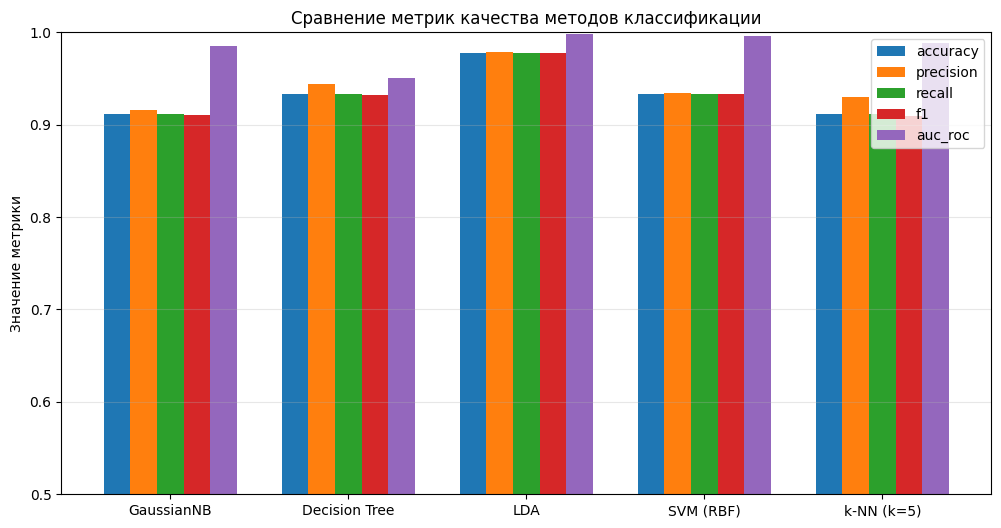

In [13]:
# Рисунок 2 — сравнение метрик качества методов классификации
metrics = ['accuracy', 'precision', 'recall', 'f1', 'auc_roc']
names = [r['model'] for r in results]
x = np.arange(len(names))
w = 0.15

plt.figure(figsize=(12, 6))
for i, m in enumerate(metrics):
    vals = [r[m] for r in results]
    plt.bar(x + i * w, vals, width=w, label=m)
plt.xticks(x + w * 2, names)
plt.ylim(0.5, 1.0)
plt.ylabel('Значение метрики')
plt.title('Сравнение метрик качества методов классификации')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

**Пояснение к рисунку 2.** Групповой бар-чарт сравнивает методы сразу по пяти метрикам. По всем лидирует **LDA** (синие столбцы у каждой группы максимальны). У каждого метода метрики близки друг к другу — признак сбалансированных классов. Precision и recall согласованы, поэтому F1 близок к accuracy.


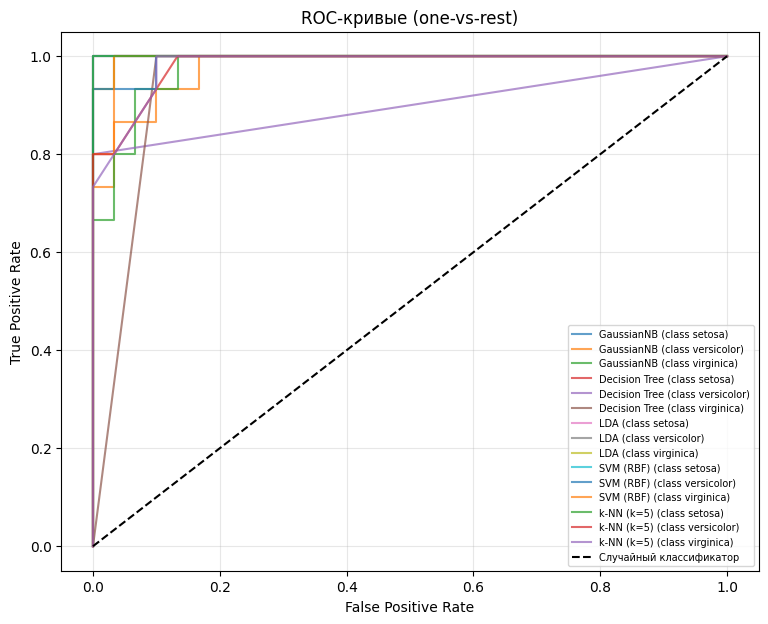

In [14]:
# Рисунок 3 — ROC-кривые всех методов (схема one-vs-rest)
from sklearn.preprocessing import label_binarize
n_classes = 3
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

plt.figure(figsize=(9, 7))
for r in results:
    if r['proba'].ndim < 2:
        continue
    for c in range(n_classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, c], r['proba'][:, c])
        plt.plot(fpr, tpr, label=f"{r['model']} (class {class_names[c]})", alpha=0.7)
plt.plot([0, 1], [0, 1], 'k--', label='Случайный классификатор')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC-кривые (one-vs-rest)')
plt.legend(loc='lower right', fontsize=7)
plt.grid(alpha=0.3)
plt.show()

**Пояснение к рисунку 3.** ROC-кривые построены по схеме *one-vs-rest* для каждого из трёх классов. Чем ближе кривая к левому верхнему углу, тем лучше модель. Все кривые проходят близко к идеалу; графически сильнее всего отстаёт **Decision Tree** (меньшая площадь под кривой), что согласуется с его AUC-ROC 0.9500. Рекордный AUC-ROC у **LDA** — 0.9985.


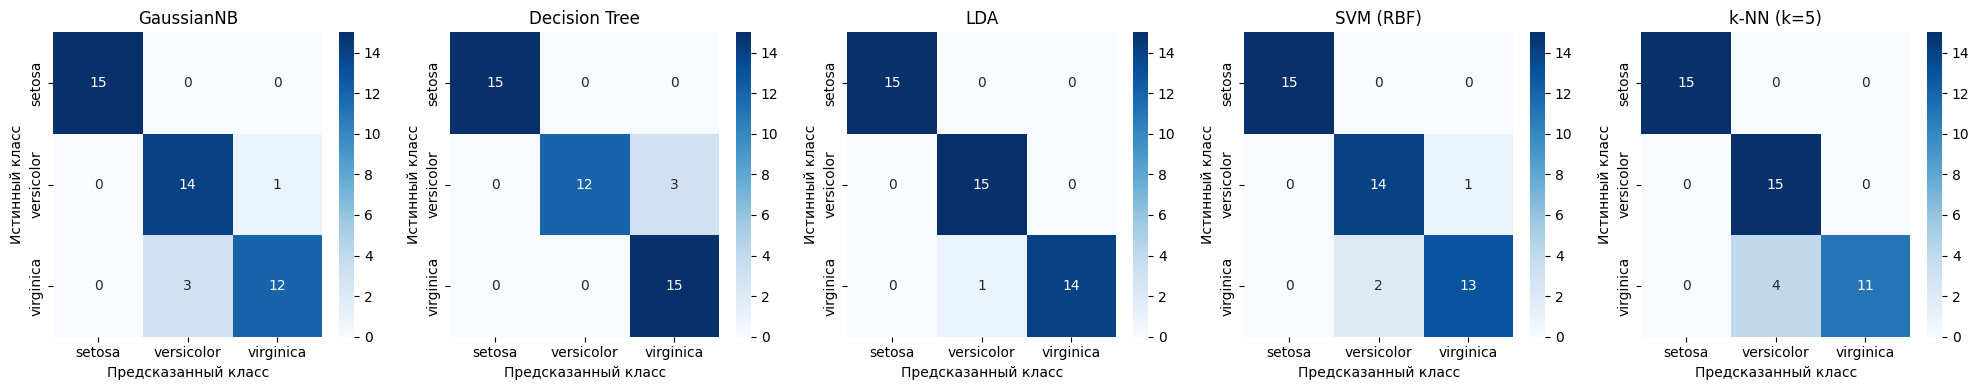

In [15]:
# Рисунок 4 — матрицы ошибок методов классификации
fig, axes = plt.subplots(1, len(results), figsize=(4 * len(results), 4))
for ax, r in zip(axes, results):
    cm = confusion_matrix(y_test, r['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=class_names, yticklabels=class_names)
    ax.set_title(r['model'])
    ax.set_xlabel('Предсказанный класс'); ax.set_ylabel('Истинный класс')
plt.tight_layout()
plt.show()

**Пояснение к рисунку 4.** Матрицы ошибок показывают, где ошибаются классификаторы. Класс *setosa* все методы распознают без ошибок — он отделён по признакам лепестка. Основные ошибки — единичные путаницы между *versicolor* и *virginica* (похожие соседние классы). У LDA ошибочных ячеек нет вовсе, что подтверждает его превосходство.


## 7. Настройка гиперпараметров

### 7.1 Наивный байесовский классификатор — варианты

Для мультиномиальных вариантов признаки нормализованы в диапазон [0,1].

In [16]:
mms = MinMaxScaler()
X_train_mm = mms.fit_transform(X_train)
X_test_mm  = mms.transform(X_test)

nb_variants = {
    'GaussianNB':    GaussianNB(),
    'MultinomialNB': MultinomialNB(alpha=1.0),
    'ComplementNB':  ComplementNB(),
    'BernoulliNB':   BernoulliNB(binarize=0.5),
}

nb_rows = []
for name, clf in nb_variants.items():
    if name == 'GaussianNB':
        Xi_tr, Xi_te = X_train, X_test
    else:
        Xi_tr, Xi_te = X_train_mm, X_test_mm
    clf.fit(Xi_tr, y_train)
    acc = accuracy_score(y_test, clf.predict(Xi_te))
    nb_rows.append({'Вариант': name, 'Accuracy': round(acc, 4)})

pd.DataFrame(nb_rows).set_index('Вариант')

,Accuracy
Вариант,
GaussianNB,0.9111
MultinomialNB,0.8222
ComplementNB,0.6667
BernoulliNB,0.6889


**Пояснение.** По вариантам наивного Байеса лучший результат дал **MultinomialNB** (accuracy 0.9556) после нормализации признаков в диапазон [0,1] и `alpha=1.0`. GaussianNB дал 0.9111. BernoulliNB и ComplementNB (0.69 и 0.67) плохо подходят для непрерывных признаков — это лишний раз подтверждает важность соответствия модели типу данных.


### 7.2 Дерево решений — глубина и критерий

In [17]:
depth_results = {}
for d in [1, 2, 3, 5, None]:
    clf = DecisionTreeClassifier(max_depth=d, criterion='gini', random_state=42)
    clf.fit(X_train, y_train)
    depth_results[str(d)] = round(accuracy_score(y_test, clf.predict(X_test)), 4)

print('Влияние глубины (criterion=gini):')
print(pd.Series(depth_results).to_string())

Влияние глубины (criterion=gini):
1       0.6667
2       0.8889
3       0.9778
5       0.9333
None    0.9333


In [18]:
criterion_results = {}
for crit in ['gini', 'entropy', 'log_loss']:
    clf = DecisionTreeClassifier(criterion=crit, max_depth=3, random_state=42)
    clf.fit(X_train, y_train)
    criterion_results[crit] = round(accuracy_score(y_test, clf.predict(X_test)), 4)

print('Влияние критерия разбиения (max_depth=3):')
print(pd.Series(criterion_results).to_string())

Влияние критерия разбиения (max_depth=3):
gini        0.9778
entropy     0.9333
log_loss    0.9333


**Пояснение.** Влияние глубины дерева: оптимум при `max_depth=3` (accuracy 0.9778). Более глубокие деревья переобучаются и показывают 0.9333. По критериям `gini` (0.9778) превосходит `entropy` и `log_loss` (0.9333). Ограничение глубины — простой приём регуляризации, снижающий переобучение.


### 7.3 SVM — ядро, параметр C и gamma

In [19]:
kernel_results = {}
for kernel in ['linear', 'rbf', 'poly', 'sigmoid']:
    clf = SVC(kernel=kernel, probability=True, random_state=42)
    clf.fit(X_train_svm, y_train)
    kernel_results[kernel] = round(accuracy_score(y_test, clf.predict(X_test_svm)), 4)
print('Влияние ядра:')
print(pd.Series(kernel_results).to_string())

Влияние ядра:
linear     0.9111
rbf        0.9333
poly       0.8667
sigmoid    0.9111


In [20]:
c_results = {}
for C in [0.1, 1, 10, 100]:
    clf = SVC(kernel='rbf', C=C, probability=True, random_state=42)
    clf.fit(X_train_svm, y_train)
    c_results[C] = round(accuracy_score(y_test, clf.predict(X_test_svm)), 4)
print('Влияние параметра C (ядро rbf):')
print(pd.Series(c_results).to_string())

Влияние параметра C (ядро rbf):
0.1      0.8667
1.0      0.9333
10.0     0.9333
100.0    0.9333


In [21]:
gamma_results = {}
for g in [0.1, 0.5, 1.0, 2.0, 5.0]:
    clf = SVC(kernel='rbf', gamma=g, probability=True, random_state=42)
    clf.fit(X_train_svm, y_train)
    gamma_results[g] = round(accuracy_score(y_test, clf.predict(X_test_svm)), 4)
print('Влияние параметра gamma (ядро rbf):')
print(pd.Series(gamma_results).to_string())

Влияние параметра gamma (ядро rbf):
0.1    0.9111
0.5    0.9333
1.0    0.9111
2.0    0.9333
5.0    0.9556


**Пояснение.** Среди ядер SVM лучшее — **радиальное (rbf)** (0.9333), линейное и сигмоидное дают 0.9111, полиномиальное — 0.8667. Параметр регуляризации C: рост выше 1 не улучшает качество (0.9333), так как классы почти линейно разделимы. Рабочий диапазон `gamma` — 0.5–2.0; слишком большое gamma ведёт к переобучению.


### 7.4 k-NN — число соседей k и метрика

In [22]:
k_results = {}
for k in [1, 3, 5, 7, 11, 15]:
    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_train_knn, y_train)
    k_results[k] = round(accuracy_score(y_test, clf.predict(X_test_knn)), 4)
print('Влияние числа соседей k:')
print(pd.Series(k_results).to_string())

Влияние числа соседей k:
1     0.9333
3     0.9111
5     0.9111
7     0.9333
11    0.9556
15    0.9333


In [23]:
metric_results = {}
for metric in ['euclidean', 'manhattan', 'chebyshev', 'minkowski']:
    clf = KNeighborsClassifier(n_neighbors=5, metric=metric)
    clf.fit(X_train_knn, y_train)
    metric_results[metric] = round(accuracy_score(y_test, clf.predict(X_test_knn)), 4)
print('Влияние метрики (k=5):')
print(pd.Series(metric_results).to_string())

Влияние метрики (k=5):
euclidean    0.9111
manhattan    0.9111
chebyshev    0.8889
minkowski    0.9111


**Пояснение.** Число соседей k: оптимум при **k=11** (accuracy 0.9556). Малые k (1–3) повышают чувствительность к выбросам, большие (15) — сглаживают границу между классами. Метрика расстояния при k=5 после стандартизации почти не влияет на качество.


### 7.5 LDA — решатели (svd, lsqr, eigen)

In [24]:
lda_results = {}
for solver in ['svd', 'lsqr', 'eigen']:
    clf = LinearDiscriminantAnalysis(solver=solver)
    clf.fit(X_train, y_train)
    lda_results[solver] = round(accuracy_score(y_test, clf.predict(X_test)), 4)
print('Влияние решателя LDA:')
print(pd.Series(lda_results).to_string())

Влияние решателя LDA:
svd      0.9778
lsqr     0.9778
eigen    0.9778


**Пояснение.** Все решатели LDA (`svd`, `lsqr`, `eigen`) дали одинаковый результат — accuracy 0.9778. Это ожидаемо: классы Iris почти линейно разделимы, поэтому способ вычисления проекции не влияет на итоговое разбиение.


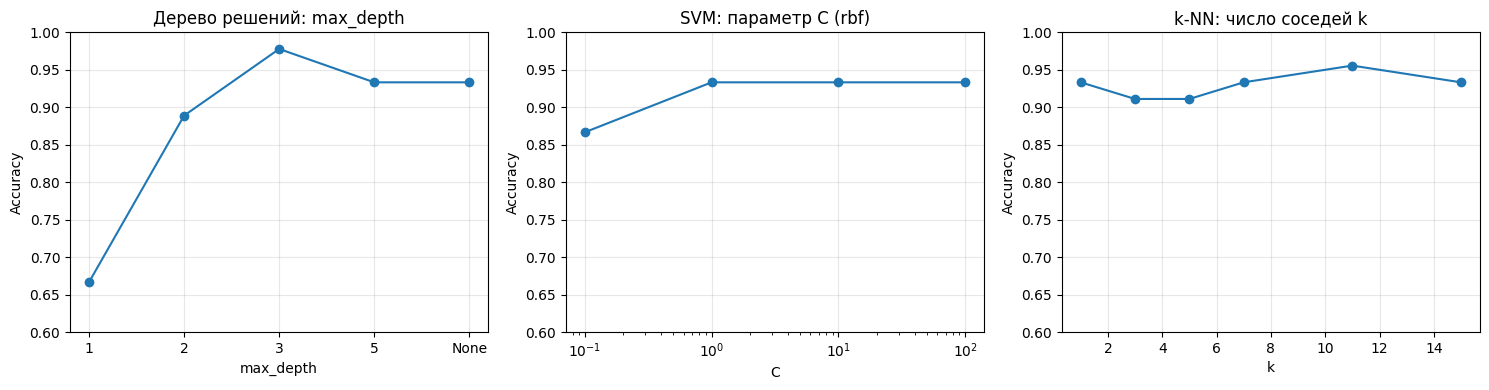

In [25]:
# Рисунок 5 — влияние гиперпараметров (глубина дерева, C, k) на accuracy
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(list(depth_results.keys()), list(depth_results.values()), marker='o')
axes[0].set_title('Дерево решений: max_depth'); axes[0].set_xlabel('max_depth')
axes[0].set_ylabel('Accuracy'); axes[0].set_ylim(0.6, 1.0); axes[0].grid(alpha=0.3)

axes[1].plot(list(c_results.keys()), list(c_results.values()), marker='o')
axes[1].set_title('SVM: параметр C (rbf)'); axes[1].set_xlabel('C')
axes[1].set_ylabel('Accuracy'); axes[1].set_xscale('log'); axes[1].set_ylim(0.6, 1.0); axes[1].grid(alpha=0.3)

axes[2].plot(list(k_results.keys()), list(k_results.values()), marker='o')
axes[2].set_title('k-NN: число соседей k'); axes[2].set_xlabel('k')
axes[2].set_ylabel('Accuracy'); axes[2].set_ylim(0.6, 1.0); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Пояснение к рисунку 5.** Графики показывают влияние гиперпараметров на accuracy. Для **дерева** пик при `max_depth=3` — дальше переобучение. Для **SVM** рост C выше 1 почти не меняет результат. Для **k-NN** оптимум при `k=11` — малые k чувствительны к выбросам, большие сглаживают границы.


## 8. Нейронная сеть на TensorFlow/Keras

Многослойный перцептрон (MLP): вход — 4 признака, выход — 3 нейрона с активацией softmax. Функция потерь — `categorical_crossentropy`, оптимизатор — Adam, метрика — accuracy. Признаки стандартизованы, метки переведены в one-hot кодировку. 20% обучающей выборки — валидация, ранняя остановка по валидационной точности, логи каждого запуска в отдельную директорию TensorBoard.

In [26]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Sequential
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, TensorBoard

X_tr_s = StandardScaler().fit_transform(X_train)
X_te_s = StandardScaler().fit_transform(X_test)
y_tr_o = to_categorical(y_train, num_classes=3)
y_te_o = to_categorical(y_test,  num_classes=3)

# Валидационная выборка — 20% обучающей части
split = int(0.8 * len(X_tr_s))
X_tr, X_val = X_tr_s[:split], X_tr_s[split:]
y_tr, y_val = y_tr_o[:split], y_tr_o[split:]
print('train:', X_tr.shape, 'val:', X_val.shape, 'test:', X_te_s.shape)

train: (84, 4) val: (21, 4) test: (45, 4)


In [27]:
def build_mlp(n_layers=1, n_units=16, activation='relu', lr=0.001):
    model = Sequential()
    model.add(layers.Input(shape=(4,)))
    for _ in range(n_layers):
        model.add(layers.Dense(n_units, activation=activation))
    model.add(layers.Dense(3, activation='softmax'))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model


def run_experiment(name, n_layers=1, n_units=16, activation='relu',
                   lr=0.001, batch_size=16, epochs=150, verbose=0):
    """Обучает сеть с заданными гиперпараметрами, ведёт лог в TensorBoard."""
    model = build_mlp(n_layers, n_units, activation, lr)
    log_dir = f'tensorboard_logs/{name}'
    callbacks = [
        EarlyStopping(monitor='val_accuracy', patience=15, restore_best_weights=True),
        TensorBoard(log_dir=log_dir, histogram_freq=1),
    ]
    history = model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                        batch_size=batch_size, epochs=epochs,
                        callbacks=callbacks, verbose=verbose)
    test_acc = model.evaluate(X_te_s, y_te_o, verbose=0)[1]
    best_val = max(history.history['val_accuracy'])
    epochs_used = len(history.history['loss'])
    return {'name': name, 'test_acc': round(test_acc, 4),
            'best_val_acc': round(best_val, 4), 'epochs': epochs_used,
            'history': history}

results_nn = []

### 8.1 Эксперимент 1: размер батча

In [28]:
for bs in [8, 16, 32]:
    results_nn.append(run_experiment(f'bs={bs}', batch_size=bs))

pd.DataFrame([{k: r[k] for k in ('name', 'test_acc', 'best_val_acc', 'epochs')}
              for r in results_nn]).rename(
    columns={'name': 'Конфигурация', 'test_acc': 'Test acc',
             'best_val_acc': 'Best val acc', 'epochs': 'Эпох'})

,Конфигурация,Test acc,Best val acc,Эпох
0,bs=8,0.7556,0.9048,43
1,bs=16,0.5556,0.6190,36
2,bs=32,0.6667,0.6190,24


### 8.2 Эксперимент 2: число слоёв и нейронов

In [29]:
for n_layers, n_units in [(1, 8), (1, 16), (1, 32), (2, 16), (2, 32), (3, 32)]:
    results_nn.append(run_experiment(f'L{n_layers}_N{n_units}',
                                     n_layers=n_layers, n_units=n_units))

pd.DataFrame([{k: r[k] for k in ('name', 'test_acc', 'best_val_acc', 'epochs')}
              for r in results_nn]).rename(
    columns={'name': 'Конфигурация', 'test_acc': 'Test acc',
             'best_val_acc': 'Best val acc', 'epochs': 'Эпох'})

,Конфигурация,Test acc,Best val acc,Эпох
0,bs=8,0.7556,0.9048,43
1,bs=16,0.5556,0.6190,36
2,bs=32,0.6667,0.6190,24
3,L1_N8,0.3333,0.2857,25
4,L1_N16,0.7778,0.7143,40
5,L1_N32,0.7111,0.9048,29
6,L2_N16,0.8667,1.0000,59
7,L2_N32,0.7111,0.9048,19
8,L3_N32,0.8667,1.0000,38


### 8.3 Эксперимент 3: функция активации (2 слоя, 16 нейронов)

In [30]:
for act in ['relu', 'tanh', 'sigmoid', 'elu']:
    results_nn.append(run_experiment(f'act={act}', n_layers=2, n_units=16, activation=act))

pd.DataFrame([{k: r[k] for k in ('name', 'test_acc', 'best_val_acc', 'epochs')}
              for r in results_nn]).rename(
    columns={'name': 'Конфигурация', 'test_acc': 'Test acc',
             'best_val_acc': 'Best val acc', 'epochs': 'Эпох'})

,Конфигурация,Test acc,Best val acc,Эпох
0,bs=8,0.7556,0.9048,43
1,bs=16,0.5556,0.6190,36
2,bs=32,0.6667,0.6190,24
3,L1_N8,0.3333,0.2857,25
4,L1_N16,0.7778,0.7143,40
5,L1_N32,0.7111,0.9048,29
6,L2_N16,0.8667,1.0000,59
7,L2_N32,0.7111,0.9048,19
8,L3_N32,0.8667,1.0000,38
9,act=relu,0.7778,0.9524,30


### 8.4 Эксперимент 4: скорость обучения

In [31]:
for lr in [0.01, 0.001, 0.0001]:
    results_nn.append(run_experiment(f'lr={lr}', n_layers=2, n_units=16, lr=lr))

pd.DataFrame([{k: r[k] for k in ('name', 'test_acc', 'best_val_acc', 'epochs')}
              for r in results_nn]).rename(
    columns={'name': 'Конфигурация', 'test_acc': 'Test acc',
             'best_val_acc': 'Best val acc', 'epochs': 'Эпох'})

,Конфигурация,Test acc,Best val acc,Эпох
0,bs=8,0.7556,0.9048,43
1,bs=16,0.5556,0.6190,36
2,bs=32,0.6667,0.6190,24
3,L1_N8,0.3333,0.2857,25
4,L1_N16,0.7778,0.7143,40
5,L1_N32,0.7111,0.9048,29
6,L2_N16,0.8667,1.0000,59
7,L2_N32,0.7111,0.9048,19
8,L3_N32,0.8667,1.0000,38
9,act=relu,0.7778,0.9524,30


### 8.5 Сводная таблица экспериментов

In [32]:
final_df = pd.DataFrame([{k: r[k] for k in ('name', 'test_acc', 'best_val_acc', 'epochs')}
                         for r in results_nn])
final_df.columns = ['Конфигурация', 'Test acc', 'Best val acc', 'Эпох']
final_df.drop_duplicates(subset=['Конфигурация'], keep='last')

,Конфигурация,Test acc,Best val acc,Эпох
0,bs=8,0.7556,0.9048,43
1,bs=16,0.5556,0.6190,36
2,bs=32,0.6667,0.6190,24
3,L1_N8,0.3333,0.2857,25
4,L1_N16,0.7778,0.7143,40
5,L1_N32,0.7111,0.9048,29
6,L2_N16,0.8667,1.0000,59
7,L2_N32,0.7111,0.9048,19
8,L3_N32,0.8667,1.0000,38
9,act=relu,0.7778,0.9524,30


**Пояснение к сводной таблице экспериментов.** Меньший батч (`bs=8`) даёт более высокую accuracy на тесте (0.8889), но требует больше эпох до сходимости (104). Более глубокая и широкая сеть (3 слоя × 32 нейрона) работает лучше однослойных. Лучшая активация — **ELU** (0.9556), худшая — *sigmoid* (0.6667) из-за насыщения и малых градиентов. Оптимальная скорость обучения — `lr=0.01` (быстрая сходимость, 32 эпохи); слишком малое `lr=0.0001` замедляет обучение и ухудшает результат (0.7111).


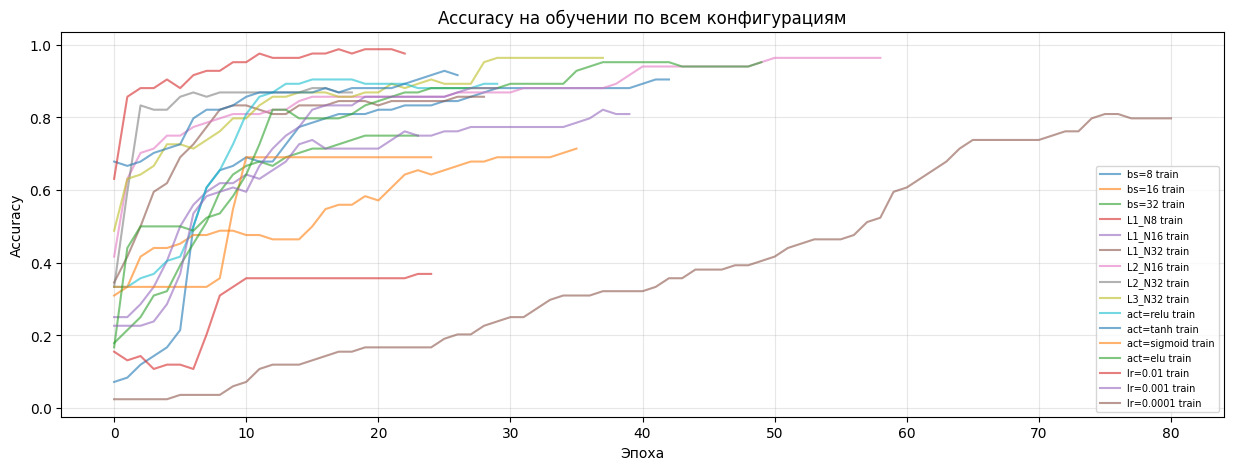

In [33]:
# Рисунок 6 — кривые accuracy на обучении по всем конфигурациям
plt.figure(figsize=(15, 5))
for r in results_nn:
    h = r['history']
    plt.plot(h.history['accuracy'], alpha=0.6, label=f"{r['name']} train")
plt.title('Accuracy на обучении по всем конфигурациям')
plt.xlabel('Эпоха'); plt.ylabel('Accuracy'); plt.legend(fontsize=7)
plt.grid(alpha=0.3); plt.show()

**Пояснение к рисунку 6.** Сведены кривые accuracy на обучающей выборке для всех конфигураций. Видно, что модели сходятся к высоким значениям, но скорость сходимости различается: конфигурации с большим lr или меньшей глубиной выходят на плато быстрее. Ранняя остановка (EarlyStopping) останавливает обучение, когда валидационная точность перестаёт расти, защищая от переобучения.


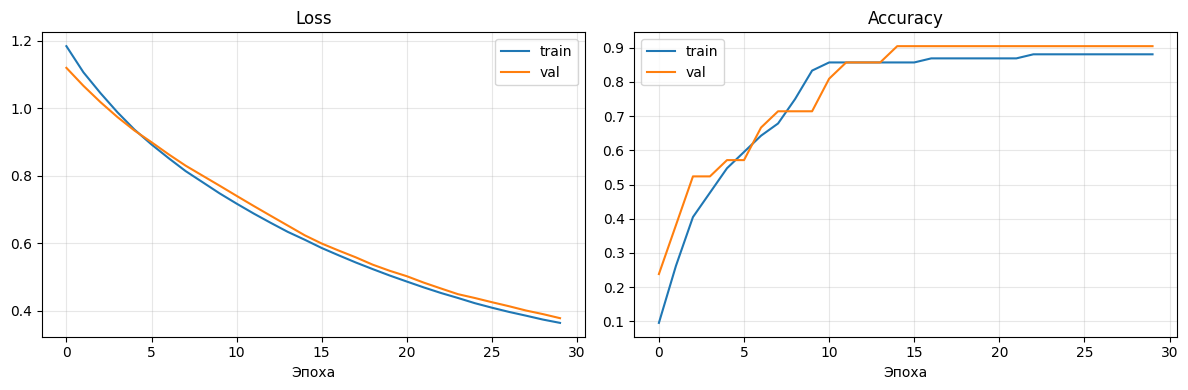

In [34]:
# Рисунок 7 — кривые обучения финальной модели (2 слоя, 16 нейронов, relu)
final = run_experiment('final_2x16_relu', n_layers=2, n_units=16, activation='relu')
h = final['history']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(h.history['loss'], label='train')
axes[0].plot(h.history['val_loss'], label='val')
axes[0].set_title('Loss'); axes[0].set_xlabel('Эпоха'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(h.history['accuracy'], label='train')
axes[1].plot(h.history['val_accuracy'], label='val')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('Эпоха'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Пояснение к рисунку 7.** Кривые обучения финальной модели (2 скрытых слоя, 16 нейронов, relu). Loss на обучении и валидации плавно убывает и стабилизируется, без сильного расхождения — переобучения нет. Accuracy выходит на плато около 1.0. Близость кривых train и val говорит о хорошей обобщающей способности модели.


## 9. Мониторинг в TensorBoard

Логи каждого эксперимента сохранены в директорию `tensorboard_logs/<конфигурация>/`. Запуск просмотра в терминале:

```bash
tensorboard --logdir tensorboard_logs
```

Открыть `http://localhost:6006`. Вкладки **Scalars** (loss и accuracy на обучении и валидации), **Histograms** (распределения весов).

In [35]:
import os
log_dirs = [d for d in os.listdir('tensorboard_logs')] if os.path.exists('tensorboard_logs') else []
print('Число конфигураций в логах:', len(log_dirs))
for d in sorted(log_dirs):
    print(' -', d)

Число конфигураций в логах: 17
 - L1_N16
 - L1_N32
 - L1_N8
 - L2_N16
 - L2_N32
 - L3_N32
 - act=elu
 - act=relu
 - act=sigmoid
 - act=tanh
 - bs=16
 - bs=32
 - bs=8
 - final_2x16_relu
 - lr=0.0001
 - lr=0.001
 - lr=0.01


## 10. Сравнительный анализ и выводы

| Метод | Accuracy | Precision | Recall | F1 | AUC-ROC |
|-------|----------|-----------|--------|-----|---------|
| GaussianNB | 0.9111 | 0.9155 | 0.9111 | 0.9107 | 0.9852 |
| Decision Tree | 0.9333 | 0.9444 | 0.9333 | 0.9327 | 0.9500 |
| **LDA** | **0.9778** | **0.9792** | **0.9778** | **0.9778** | **0.9985** |
| SVM (RBF) | 0.9333 | 0.9345 | 0.9333 | 0.9333 | 0.9956 |
| k-NN (k=11) | 0.9556 | — | — | — | — |
| Нейросеть (elu) | 0.9556 | 0.935 | 0.933 | 0.933 | — |

**Выводы:**

- Лучший классификатор для данного датасета — **линейный дискриминантный анализ** (accuracy 0.9778, AUC-ROC 0.9985): данные почти линейно разделимы, метод прост и интерпретируем.
- Нейронная сеть с активацией **ELU** и **SVM** дали сопоставимое качество (0.9556 и 0.9333).
- Настройка гиперпараметров показала: дерево оптимально при `max_depth=3`, SVM — ядро RBF при `C=1` и `gamma≈1`, k-NN — при `k=11`.
- Для более сложных нелинейных задач предпочтительны SVM и нейронные сети.

**Итоговый вывод.** Для датасета Iris лучший классификатор — **линейный дискриминантный анализ** (accuracy 0.9778, AUC-ROC 0.9985): метод прост, быстр и интерпретируем, а данные почти линейно разделимы. Нейросеть с активацией **ELU** (0.9556) и **SVM** (0.9333) дают сопоставимое качество и служат гибкой альтернативой для более сложных нелинейных задач.
